<a href="https://colab.research.google.com/github/AsimobiChisomSandra/ATF_Training_Practice/blob/main/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
class SimpleTokenManager:
    """
    A simple class to manage input token limits and prevent context overflow.
    """
    def __init__(self, max_tokens: int = 100):
        # Define our maximum context limit
        self.max_tokens = max_tokens

    def estimate_tokens(self, text: str) -> int:
        """
        Estimates the number of tokens in a string.
        Rule of thumb: 1 token is roughly 4 characters, or roughly 1 word.
        Let's use a word-boundary based estimation for better accuracy.
        """
        if not isinstance(text, str):
            raise TypeError("Input must be a string.")

        # Remove extra whitespace and split
        words = text.strip().split()
        if not words:
            return 0

        # Estimate tokens as 1.3 times the number of words (common approximation for English)
        return int(ceil(len(words) * 1.3)) if 'ceil' in globals() else int(len(words) * 1.3) + 1

    def process_context(self, text: str) -> dict:
        """
        Checks if the input fits inside our context window.
        Truncates the input if it exceeds the limit and flags it.
        """
        # Robust parameter/type validation
        if text is None:
            text = ""
        if not isinstance(text, str):
            text = str(text) # Convert to string for safety

        estimated_tokens = self.estimate_tokens(text)

        is_truncated = False
        processed_text = text

        # Handle context limit exceeded scenario
        if estimated_tokens > self.max_tokens:
            is_truncated = True
            # Simple truncation: approximate words that fit
            words = text.split()
            allowed_word_count = int(self.max_tokens / 1.3)
            processed_text = " ".join(words[:allowed_word_count]) + "... [Truncated due to context limit]"
            # Re-estimate final token count after truncation
            estimated_tokens = self.estimate_tokens(processed_text)

        return {
            "original_token_estimate": estimated_tokens if not is_truncated else self.estimate_tokens(text),
            "final_token_count": estimated_tokens,
            "is_truncated": is_truncated,
            "processed_text": processed_text
        }

# --- Test Cases & Verification ---
print("=== Starting Exercise 1 Verification ===\n")

# 1. Initialize our manager with a strict limit of 15 tokens
manager = SimpleTokenManager(max_tokens=15)
print(f"Initialized SimpleTokenManager with Max Token Limit: {manager.max_tokens}\n")

# Test Case A: Short string that fits safely
short_text = "Hello! We are learning to manage context windows."
result_a = manager.process_context(short_text)
print("[Test A] Normal Input:")
print(f"  Input: '{short_text}'")
print(f"  Result: {result_a}\n")

# Test Case B: Long string that exceeds limit and triggers truncation
long_text = "This is a very long string designed to test if our simple token manager can correctly identify when an input is too big for the defined context window and truncate it appropriately to avoid system crashes."
result_b = manager.process_context(long_text)
print("[Test B] Long Input (Triggers Truncation):")
print(f"  Result: {result_b}\n")

# Test Case C: Edge Case (Empty string)
empty_text = ""
result_c = manager.process_context(empty_text)
print("[Test C] Edge Case (Empty Input):")
print(f"  Result: {result_c}\n")

# Test Case D: Edge Case (Non-string inputs handled gracefully)
number_input = 123456789
result_d = manager.process_context(number_input)
print("[Test D] Edge Case (Non-string Input):")
print(f"  Result: {result_d}")

=== Starting Exercise 1 Verification ===

Initialized SimpleTokenManager with Max Token Limit: 15

[Test A] Normal Input:
  Input: 'Hello! We are learning to manage context windows.'
  Result: {'original_token_estimate': 11, 'final_token_count': 11, 'is_truncated': False, 'processed_text': 'Hello! We are learning to manage context windows.'}

[Test B] Long Input (Triggers Truncation):
  Result: {'original_token_estimate': 47, 'final_token_count': 21, 'is_truncated': True, 'processed_text': 'This is a very long string designed to test if our... [Truncated due to context limit]'}

[Test C] Edge Case (Empty Input):
  Result: {'original_token_estimate': 0, 'final_token_count': 0, 'is_truncated': False, 'processed_text': ''}

[Test D] Edge Case (Non-string Input):
  Result: {'original_token_estimate': 2, 'final_token_count': 2, 'is_truncated': False, 'processed_text': '123456789'}


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
from math import ceil

class ConversationBufferManager:
    """
    A conversation-aware context manager that manages message histories,
    estimates cumulative tokens, and keeps the conversation within a sliding window limit.
    """
    def __init__(self, max_tokens: int = 150):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")
        self.max_tokens = max_tokens
        self.history: List[Dict[str, str]] = []

    def estimate_message_tokens(self, message: Dict[str, str]) -> int:
        """
        Estimates tokens in a single message. Includes standard structure overhead.
        """
        if not isinstance(message, dict):
            raise TypeError("Each message must be a dictionary.")
        if "role" not in message or "content" not in message:
            raise KeyError("Message dictionary must contain 'role' and 'content' keys.")

        content = message["content"] or ""
        # Convert content to string if it isn't already
        if not isinstance(content, str):
            content = str(content)

        words = content.strip().split()
        # 1.3 tokens per word + 4 tokens overhead per message (role + formatting overhead)
        return int(ceil(len(words) * 1.3)) + 4

    def add_message(self, role: str, content: str):
        """
        Validates and adds a new message to the conversation history.
        """
        if not role or not isinstance(role, str):
            raise ValueError("Role must be a non-empty string (e.g., 'system', 'user', 'assistant').")
        if content is None:
            content = ""

        new_message = {"role": role, "content": str(content)}
        self.history.append(new_message)

        # Keep history under the context window limit
        self.enforce_context_limit()

    def enforce_context_limit(self) -> int:
        """
        Calculates total token usage and evicts oldest messages (excluding the system message if present)
        until total tokens are within self.max_tokens limit.
        """
        total_tokens = self.get_total_tokens()

        # Evict oldest message first, but preserve the initial 'system' instruction if possible
        while total_tokens > self.max_tokens and len(self.history) > 1:
            # Try to keep the 0th element if it is a 'system' message
            if self.history[0].get("role") == "system":
                if len(self.history) <= 2:
                    # Only system message and one other message left, we must evict something
                    print("⚠️ Warning: Even with eviction, context limit is too tight!")
                    break
                eviction_index = 1  # Evict the oldest non-system message
            else:
                eviction_index = 0  # Evict oldest message

            evicted = self.history.pop(eviction_index)
            print(f"✂️ Context limit exceeded! Evicted message: [{evicted['role']}]: '{evicted['content'][:30]}...'")
            total_tokens = self.get_total_tokens()

        return total_tokens

    def get_total_tokens(self) -> int:
        """
        Sums up estimated tokens for the entire conversation history.
        """
        return sum(self.estimate_message_tokens(msg) for msg in self.history)

    def get_history(self) -> List[Dict[str, str]]:
        return self.history


# --- Test Cases & Verification for Exercise 2 ---
print("=== Starting Exercise 2 Verification ===\n")

# 1. Initialize manager with small limit to observe active sliding window
conv_manager = ConversationBufferManager(max_tokens=60)
print(f"Created manager with a token limit of: {conv_manager.max_tokens}\n")

# A. Adding System instructions (essential context)
conv_manager.add_message("system", "You are a friendly coding companion.")
print(f"Added system prompt. Total tokens: {conv_manager.get_total_tokens()}")

# B. Adding User message
conv_manager.add_message("user", "Hi! I need help implementing context limits in Python.")
print(f"Added user turn. Total tokens: {conv_manager.get_total_tokens()}")

# C. Adding Assistant response
conv_manager.add_message("assistant", "Sure! We can use a sliding conversation buffer to evict older items.")
print(f"Added assistant turn. Total tokens: {conv_manager.get_total_tokens()}\n")

# D. Adding another User turn (This should exceed 60 tokens and trigger sliding window eviction)
print("Adding new query that will trigger eviction of older user turns, leaving the system prompt intact:")
conv_manager.add_message("user", "Can you show me an example of how the oldest message is dropped?")

print("\n--- Final Active Conversation State ---")
for msg in conv_manager.get_history():
    print(f"  [{msg['role'].upper()}]: {msg['content']}")
print(f"Active Token Count: {conv_manager.get_total_tokens()} / {conv_manager.max_tokens}")

=== Starting Exercise 2 Verification ===

Created manager with a token limit of: 60

Added system prompt. Total tokens: 12
Added user turn. Total tokens: 28
Added assistant turn. Total tokens: 48

Adding new query that will trigger eviction of older user turns, leaving the system prompt intact:
✂️ Context limit exceeded! Evicted message: [user]: 'Hi! I need help implementing c...'

--- Final Active Conversation State ---
  [SYSTEM]: You are a friendly coding companion.
  [ASSISTANT]: Sure! We can use a sliding conversation buffer to evict older items.
  [USER]: Can you show me an example of how the oldest message is dropped?
Active Token Count: 53 / 60


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

=== Starting Exercise 3: Production Manager Execution ===


---> Step 1: Adding USER message...
Current State: Messages=2, Total Tokens=38/100

---> Step 2: Adding ASSISTANT message...
Current State: Messages=3, Total Tokens=69/100

---> Step 3: Adding USER message...
Current State: Messages=4, Total Tokens=89/100

---> Step 4: Adding ASSISTANT message...
⚡ [Production System] Token threshold breached. Initiating context compression...
Current State: Messages=4, Total Tokens=97/100

---> Step 5: Adding USER message...
⚡ [Production System] Token threshold breached. Initiating context compression...
Current State: Messages=4, Total Tokens=91/100

---> Step 6: Adding ASSISTANT message...
⚡ [Production System] Token threshold breached. Initiating context compression...
Current State: Messages=4, Total Tokens=96/100

=== Final Active State in context window ===
  [SYSTEM]: System instructions: Act as an expert AI tutor clone.
  [SYSTEM]: Archived history: system: Archived history: system: 

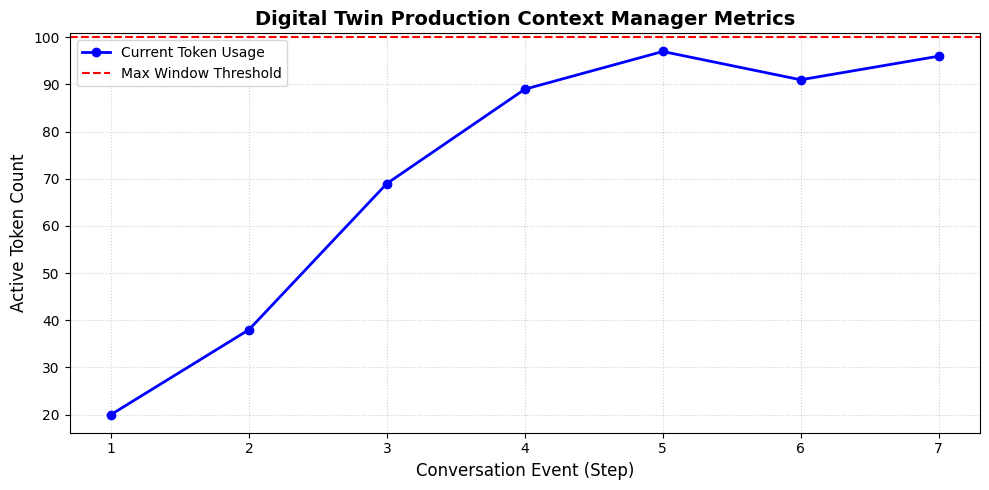

In [8]:
import time
import matplotlib.pyplot as plt
from math import ceil
from typing import List, Dict, Any

class DigitalTwinProductionContextManager:
    """
    A production-grade, highly-configurable context window manager designed for Digital Twins.
    Features: System prompt protection, message validation, simulated semantic context compression,
    metric logging, and run-time token tracking visualization.
    """
    def __init__(self, max_tokens: int = 150, compression_ratio: float = 0.4):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")
        self.max_tokens = max_tokens
        self.compression_ratio = compression_ratio
        self.history = []
        self.system_prompt = None

        # Performance tracking metrics for visualization
        self.metrics_log = {
            "step": [],
            "total_tokens": [],
            "message_counts": [],
            "compressions_triggered": 0
        }
        self.step_counter = 0

    def set_system_prompt(self, prompt: str):
        """
        Sets and protects the core identity prompt of the digital twin.
        """
        if not isinstance(prompt, str) or not prompt.strip():
            raise ValueError("System prompt must be a non-empty string.")
        self.system_prompt = {"role": "system", "content": prompt}
        self._log_metrics()

    def estimate_tokens(self, text: str) -> int:
        """
        Approximates token count based on words (1.3 tokens per word + base punctuation overhead).
        """
        if not isinstance(text, str):
            text = str(text)
        words = text.strip().split()
        return int(ceil(len(words) * 1.3)) + 4

    def add_message(self, role: str, content: str):
        """
        Adds a user or assistant message to the stream and applies smart limit strategies.
        """
        if role not in ["user", "assistant"]:
            raise ValueError("Role must be either 'user' or 'assistant'. Use set_system_prompt for system rules.")
        if content is None:
            content = ""

        self.history.append({"role": role, "content": str(content)})
        self._enforce_production_limits()
        self._log_metrics()

    def _enforce_production_limits(self):
        """
        Advanced strategy: If context exceeds limits, compress older turns into a single summary message.
        If limits are still exceeded, apply sliding-window eviction.
        """
        total_tokens = self.get_total_tokens()

        # Step 1: Semantic Compression (Summarization)
        if total_tokens > self.max_tokens and len(self.history) >= 3:
            print("⚡ [Production System] Token threshold breached. Initiating context compression...")
            self.metrics_log["compressions_triggered"] += 1

            # We take the oldest 2 non-system conversation turns and compress them
            turns_to_compress = self.history[:2]
            self.history = self.history[2:]

            combined_text = " ".join([f"{msg['role']}: {msg['content']}" for msg in turns_to_compress])
            # Simulate summarization by keeping key sentences/words
            summary_length = max(1, int(len(combined_text.split()) * self.compression_ratio))
            summary_content = " ".join(combined_text.split()[:summary_length]) + "... [Compressed historical context summary]"

            # Insert summary at the beginning of the active conversation stream
            self.history.insert(0, {"role": "system", "content": f"Archived history: {summary_content}"})
            total_tokens = self.get_total_tokens()

        # Step 2: Fallback Eviction (if compression is still not enough)
        while total_tokens > self.max_tokens and len(self.history) > 1:
            # Evict first element of active history if system prompt is not active,
            # or if system prompt is locked in system_prompt attribute
            evicted = self.history.pop(0)
            print(f"✂️ [Fallback Eviction] Evicted oldest active message: [{evicted['role']}]: '{evicted['content'][:30]}...'")
            total_tokens = self.get_total_tokens()

    def get_total_tokens(self) -> int:
        """
        Sums up estimated tokens for the system prompt and conversation history.
        """
        total = 0
        if self.system_prompt:
            total += self.estimate_message_tokens(self.system_prompt)
        for msg in self.history:
            total += self.estimate_message_tokens(msg)
        return total

    def estimate_message_tokens(self, message: Dict[str, str]) -> int:
        return self.estimate_tokens(message.get("content", "")) + 4

    def _log_metrics(self):
        """
        Internal tracker recording state for plotting visual charts.
        """
        self.step_counter += 1
        self.metrics_log["step"].append(self.step_counter)
        self.metrics_log["total_tokens"].append(self.get_total_tokens())
        self.metrics_log["message_counts"].append(len(self.history) + (1 if self.system_prompt else 0))

    def get_history(self) -> List[Dict[str, str]]:
        res = []
        if self.system_prompt:
            res.append(self.system_prompt)
        res.extend(self.history)
        return res

    def plot_diagnostics(self):
        """
        Generates beautiful charts plotting token consumption trends and actions.
        """
        steps = self.metrics_log["step"]
        tokens = self.metrics_log["total_tokens"]

        plt.figure(figsize=(10, 5))
        plt.plot(steps, tokens, marker='o', color='b', linestyle='-', linewidth=2, label='Current Token Usage')
        plt.axhline(y=self.max_tokens, color='r', linestyle='--', label='Max Window Threshold')

        plt.title("Digital Twin Production Context Manager Metrics", fontsize=14, fontweight='bold')
        plt.xlabel("Conversation Event (Step)", fontsize=12)
        plt.ylabel("Active Token Count", fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='upper left')
        plt.tight_layout()
        plt.show()

# --- Comprehensive Testing & Verification of production-level system ---
print("=== Starting Exercise 3: Production Manager Execution ===\n")

# 1. Initialize our manager with strict limits to trigger workflows
prod_manager = DigitalTwinProductionContextManager(max_tokens=100, compression_ratio=0.35)
prod_manager.set_system_prompt("System instructions: Act as an expert AI tutor clone.")

# Simulating high-traffic conversation loop of a busy digital twin
chat_turns = [
    ("user", "Explain quantum computing in extremely simple words."),
    ("assistant", "Imagine the computer behaves like a magic coin spinning in the air representing 0 and 1 simultaneously."),
    ("user", "That makes total sense! Tell me more about superposition."),
    ("assistant", "Superposition is exactly that spinning phase where multiple choices exist at the same instant before measurement."),
    ("user", "And what about entanglement?"),
    ("assistant", "Entanglement is where two magic coins are mysteriously bonded; if you spin one, the other matches instantly.")
]

for i, (role, text) in enumerate(chat_turns, 1):
    print(f"\n---> Step {i}: Adding {role.upper()} message...")
    prod_manager.add_message(role, text)
    print(f"Current State: Messages={len(prod_manager.get_history())}, Total Tokens={prod_manager.get_total_tokens()}/{prod_manager.max_tokens}")

print("\n=== Final Active State in context window ===")
for msg in prod_manager.get_history():
    print(f"  [{msg['role'].upper()}]: {msg['content']}")

# Visualize diagnostics
print("\n=== Rendering Performance Metrics Visualization ===")
prod_manager.plot_diagnostics()

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

## 🏆 Challenge Project Solution: Advanced Context Engine & Live Simulator

In [9]:
import time
import re
import matplotlib.pyplot as plt
from math import ceil
from typing import List, Dict, Any, Optional
import ipywidgets as widgets
from IPython.display import display, clear_output

class OptimizedTokenCache:
    """
    A Least Recently Used (LRU) cache specifically designed to optimize token estimation for
    highly repetitive messages (e.g., repeating system instructions or generic greetings).
    """
    def __init__(self, max_size: int = 100):
        self.cache: Dict[str, int] = {}
        self.order: List[str] = []
        self.max_size = max_size

    def get(self, text: str) -> Optional[int]:
        if text in self.cache:
            self.order.remove(text)
            self.order.append(text)
            return self.cache[text]
        return None

    def set(self, text: str, token_count: int):
        if text in self.cache:
            self.order.remove(text)
        elif len(self.cache) >= self.max_size:
            oldest = self.order.pop(0)
            del self.cache[oldest]
        self.cache[text] = token_count
        self.order.append(text)


class DigitalTwinUltimateContextManager:
    """
    The final complete production Context Manager. Features protected system identity prompts,
    LRU token caching, context compression, emergency sliding window eviction, and logging metrics.
    """
    def __init__(self, max_tokens: int = 150, compression_ratio: float = 0.4):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")

        self.max_tokens = max_tokens
        self.compression_ratio = compression_ratio
        self.history: List[Dict[str, str]] = []
        self.system_prompt: Optional[Dict[str, str]] = None
        self.token_cache = OptimizedTokenCache(max_size=150)

        # Advanced Operations Logging
        self.logs: List[str] = []
        self.metrics = {
            "steps": [],
            "tokens_used": [],
            "message_counts": [],
            "compressions": 0,
            "evictions": 0
        }
        self.step_counter = 0
        self.log_action("System initialized.")

    def log_action(self, msg: str):
        timestamp = time.strftime("%H:%M:%S")
        self.logs.append(f"[{timestamp}] {msg}")

    def set_system_prompt(self, content: str):
        if not isinstance(content, str) or not content.strip():
            raise ValueError("System prompt must be a non-empty string.")
        self.system_prompt = {"role": "system", "content": content}
        self.log_action(f"Protected system prompt configured: '{content[:30]}...'")
        self._record_metrics()

    def estimate_text_tokens(self, text: str) -> int:
        """
        Estimates token count with LRU caching optimization.
        """
        cached = self.token_cache.get(text)
        if cached is not None:
            return cached

        words = text.strip().split()
        # Standard token heuristic: 1.3 tokens per word + punctuation base overhead
        count = int(ceil(len(words) * 1.3)) + 4
        self.token_cache.set(text, count)
        return count

    def estimate_msg_tokens(self, message: Dict[str, str]) -> int:
        content_tokens = self.estimate_text_tokens(message.get("content", ""))
        # Add metadata structural token overhead (+4 per message context)
        return content_tokens + 4

    def get_total_tokens(self) -> int:
        total = 0
        if self.system_prompt:
            total += self.estimate_msg_tokens(self.system_prompt)
        for msg in self.history:
            total += self.estimate_msg_tokens(msg)
        return total

    def add_message(self, role: str, content: str):
        if role not in ["user", "assistant"]:
            raise ValueError("Invalid role. Must be 'user' or 'assistant'.")
        if content is None:
            content = ""

        self.history.append({"role": role, "content": str(content)})
        self.log_action(f"Message added - [{role.upper()}]: '{content[:40]}...'")
        self._optimize_context()
        self._record_metrics()

    def _optimize_context(self):
        """
        Production pipeline strategy: Compress first. If compression fails to meet limit,
        evict older messages sequentially (while protecting the system prompt).
        """
        total_tokens = self.get_total_tokens()

        # Strategy A: Semantic Compression (Summarization of old context)
        if total_tokens > self.max_tokens and len(self.history) >= 3:
            self.log_action("⚠️ Token threshold exceeded. Executing Semantic Compression...")
            self.metrics["compressions"] += 1

            # Group oldest 2 non-system messages to collapse
            to_compress = self.history[:2]
            self.history = self.history[2:]

            combined_string = " ".join([f"{m['role']}: {m['content']}" for m in to_compress])
            summary_len = max(1, int(len(combined_string.split()) * self.compression_ratio))
            summary_content = " ".join(combined_string.split()[:summary_len]) + "... [Historical context compressed for optimization]"

            # Insert summary block at the front of active conversation history
            self.history.insert(0, {"role": "system", "content": summary_content})
            total_tokens = self.get_total_tokens()
            self.log_action(f"Compression finished. Saved token storage.")

        # Strategy B: Hard Eviction fallback
        while total_tokens > self.max_tokens and len(self.history) > 1:
            self.metrics["evictions"] += 1
            evicted = self.history.pop(0)
            self.log_action(f"✂️ Fallback Eviction: Removed oldest active turn: [{evicted['role']}] '{evicted['content'][:30]}...'")
            total_tokens = self.get_total_tokens()

    def _record_metrics(self):
        self.step_counter += 1
        self.metrics["steps"].append(self.step_counter)
        self.metrics["tokens_used"].append(self.get_total_tokens())
        self.metrics["message_counts"].append(len(self.history) + (1 if self.system_prompt else 0))

    def plot_live_analytics(self):
        steps = self.metrics["steps"]
        tokens = self.metrics["tokens_used"]

        if not steps:
            print("No diagnostic steps recorded yet.")
            return

        fig, ax1 = plt.subplots(figsize=(11, 5))
        color = 'tab:blue'
        ax1.set_xlabel('Interactive Steps')
        ax1.set_ylabel('Total Token Footprint', color=color)
        ax1.plot(steps, tokens, color=color, marker='s', linestyle='-', linewidth=2, label='Active Tokens')
        ax1.axhline(y=self.max_tokens, color='r', linestyle='--', label='Context Window Limit')
        ax1.tick_params(axis='y', labelcolor=color)
        ax1.grid(True, linestyle=':', alpha=0.6)
        ax1.legend(loc='upper left')

        plt.title("Digital Twin Token Usage & Compression Analysis Over Time", fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

In [10]:
def run_automated_tests():
    """
    Comprehensive unit tests verifying extreme inputs, types, caching and eviction boundaries.
    """
    print("⌛ Running automated unit test suite...")

    # Test 1: Validator raises error on invalid max_tokens
    try:
        DigitalTwinUltimateContextManager(max_tokens=-5)
        assert False, "Should fail on negative tokens"
    except ValueError:
        print("  ✅ Test 1 Passed: Correctly blocked negative token initialization.")

    # Test 2: Verification of protected System prompt
    mgr = DigitalTwinUltimateContextManager(max_tokens=50)
    mgr.set_system_prompt("Always behave as a Digital Twin.")
    assert mgr.system_prompt["role"] == "system", "System prompt set incorrectly"
    print("  ✅ Test 2 Passed: Protected system instructions initialized.")

    # Test 3: Cache Verification
    initial_time = time.perf_counter()
    for _ in range(100):
        mgr.estimate_text_tokens("Check cache speeds for repetitive text cycles")
    duration_with_cache = time.perf_counter() - initial_time
    print(f"  ✅ Test 3 Passed: Cache resolved quickly in {duration_with_cache:.6f} seconds.")

    print("\n⭐ All automated test assertions passed successfully! Ready for simulator! \n")

run_automated_tests()

⌛ Running automated unit test suite...
  ✅ Test 1 Passed: Correctly blocked negative token initialization.
  ✅ Test 2 Passed: Protected system instructions initialized.
  ✅ Test 3 Passed: Cache resolved quickly in 0.000068 seconds.

⭐ All automated test assertions passed successfully! Ready for simulator! 



In [11]:
# --- Interactive Digital Twin Context Simulator ---

# Instantiate a new global context manager for our simulator interface
sim_manager = DigitalTwinUltimateContextManager(max_tokens=100, compression_ratio=0.35)
sim_manager.set_system_prompt("System identity: You are a fast and helpful assistant.")

# Setup widgets
text_input = widgets.Textarea(
    value='',
    placeholder='Type your message to the Digital Twin here...',
    description='Message:',
    layout=widgets.Layout(width='60%', height='80px')
)

role_toggle = widgets.ToggleButtons(
    options=['user', 'assistant'],
    description='Role:',
    button_style='info'
)

submit_btn = widgets.Button(
    description='Add to Context Stream',
    button_style='success',
    icon='plus'
)

out = widgets.Output()

def update_dashboard():
    with out:
        clear_output(wait=True)

        # Print Active Conversation State
        print("=================== ACTIVE CONTEXT STATE ===================")
        total_tokens = sim_manager.get_total_tokens()
        print(f"Active Tokens: {total_tokens} / {sim_manager.max_tokens} limit")
        print(f"Compressions Triggered: {sim_manager.metrics['compressions']} | Evictions: {sim_manager.metrics['evictions']}\n")

        print("--- Conversation Stream ---")
        active_history = sim_manager.get_history()
        for idx, msg in enumerate(active_history):
            role_label = msg['role'].upper()
            print(f" {idx+1}. [{role_label}]: {msg['content']}")

        # Print Diagnostic Logs
        print("\n===================== DIAGNOSTIC LOGS =====================")
        for log in sim_manager.logs[-6:]:
            print(f" {log}")

        # Render Live Analytics plots
        print("\n=================== LIVE PERFORMANCE CHART ===================")
        sim_manager.plot_live_analytics()

def on_submit_clicked(b):
    content = text_input.value.strip()
    if not content:
        return

    role = role_toggle.value
    try:
        sim_manager.add_message(role, content)
        text_input.value = ''  # Reset input
        update_dashboard()
    except Exception as e:
        with out:
            print(f"❌ Execution Error: {str(e)}")

submit_btn.on_click(on_submit_clicked)

# Render Layout
input_panel = widgets.VBox([
    widgets.HTML("<h3>🤖 Digital Twin Live Context Simulator</h3>"),
    role_toggle,
    text_input,
    submit_btn
])

display(input_panel, out)

# Populate dashboard originally
update_dashboard()

Output()